In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Regressiya modellari
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Ma'lumotlarni qayta ishlash
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model sifatini baholash
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Datasetni yuklash
df = pd.read_csv("sport_inshootlari.csv")

# Dataset haqida umumiy ma'lumot
print("Dataset o'lchami:", df.shape)
print("\nUstunlar:")
print(df.columns)

print("\nBirinchi 5 ta qator:")
display(df.head())

print("\nMa'lumot turlari:")
print(df.dtypes)

print("\nBo'sh qiymatlar:")
print(df.isnull().sum())

Dataset o'lchami: (1497, 6)

Ustunlar:
Index(['T/r', 'Hudud', 'Tuman(shahar)', 'Tashkilot', 'Sport inshoati turi',
       'Bino nomi'],
      dtype='object')

Birinchi 5 ta qator:


,T/r,Hudud,Tuman(shahar),Tashkilot,Sport inshoati turi,Bino nomi
0,1,Andijon viloyati,Baliqchi,Baliqchi tumani sport maktabi,Спорт зали,Sport zal
1,2,Farg'ona viloyati,Buvayda,Buvayda tuman sport maktabi,Futbol maydoni,Buvayda t SM markaziy o‘yingoh
2,3,Jizzax viloyati,Sharof Rashidov,Sh.Rashidov tumani sport maktabi,Futbol maydoni,Sport maktab
3,4,Jizzax viloyati,G'allaorol tumani,G`allaorol tumani 1-son sport maktabi,Спорт зали,G‘allaorol.t 1-sonli SM
4,5,Jizzax viloyati,Baxmal,Baxmal tumani sport maktabi,Спорт зали,Sport maktab



Ma'lumot turlari:
T/r                     int64
Hudud                  object
Tuman(shahar)          object
Tashkilot              object
Sport inshoati turi    object
Bino nomi              object
dtype: object

Bo'sh qiymatlar:
T/r                    0
Hudud                  0
Tuman(shahar)          0
Tashkilot              0
Sport inshoati turi    0
Bino nomi              0
dtype: int64


In [3]:
# 1. Model yaratish

# Tumanlar kesimida ma'lumotlarni guruhlash
df_model = (
    df.groupby(["Hudud", "Tuman(shahar)"])
    .agg(
        sport_inshootlari_soni=("T/r", "count"),
        tashkilotlar_soni=("Tashkilot", "nunique"),
        binolar_soni=("Bino nomi", "nunique")
    )
    .reset_index()
)

# Ustun nomlarini o'zbek tiliga o'zgartirish
df_model.rename(columns={
    "Hudud": "Viloyat",
    "Tuman(shahar)": "Tuman yoki shahar"
}, inplace=True)

# Natijani ko'rish
display(df_model.head(10))

print("Yangi dataset o'lchami:", df_model.shape)

,Viloyat,Tuman yoki shahar,sport_inshootlari_soni,tashkilotlar_soni,binolar_soni
0,Andijon viloyati,Andijon,2,1,2
1,Andijon viloyati,Andijon sh.,62,8,34
2,Andijon viloyati,Asaka,4,1,2
3,Andijon viloyati,Baliqchi,2,1,2
4,Andijon viloyati,Bo‘ston,2,1,1
5,Andijon viloyati,Buloqboshi,8,1,8
6,Andijon viloyati,Izboskan,8,1,5
7,Andijon viloyati,Jalalquduq,5,1,5
8,Andijon viloyati,Marhamat,2,1,2
9,Andijon viloyati,Oltinko`l,5,1,3


Yangi dataset o'lchami: (202, 5)


In [4]:
# 1.1. Mustaqil va bog‘liq o‘zgaruvchilarni ajratish

# Mustaqil o‘zgaruvchilar
X = df_model[["tashkilotlar_soni", "binolar_soni", "Viloyat"]]

# Bog‘liq o‘zgaruvchi
y = df_model["sport_inshootlari_soni"]

print("Mustaqil o‘zgaruvchilar:")
print(X.head())

print("\nBog‘liq o‘zgaruvchi:")
print(y.head())

Mustaqil o‘zgaruvchilar:
   tashkilotlar_soni  binolar_soni           Viloyat
0                  1             2  Andijon viloyati
1                  8            34  Andijon viloyati
2                  1             2  Andijon viloyati
3                  1             2  Andijon viloyati
4                  1             1  Andijon viloyati

Bog‘liq o‘zgaruvchi:
0     2
1    62
2     4
3     2
4     2
Name: sport_inshootlari_soni, dtype: int64


In [5]:
# 1.2. Train va Test qismlariga ajratish

# Ma'lumotlarni 80% o'qitish va 20% testga ajratish
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("O'qitish to'plami:", X_train.shape)
print("Test to'plami:", X_test.shape)

O'qitish to'plami: (161, 3)
Test to'plami: (41, 3)


In [6]:
# 2. Oddiy chiziqli regressiya va ko‘p chiziqli regressiya

# 2.1. Oddiy chiziqli regressiya - bunda bitta mustaqil o‘zgaruvchi va bitta bog‘liq o‘zgaruvchi ishlatiladi.

# Tashkilotlar soni orqali sport inshootlari sonini bashorat qilish
X_simple = df_model[["tashkilotlar_soni"]]
y_simple = df_model["sport_inshootlari_soni"]

# Train va Test to'plamlariga ajratish
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

# Model yaratish
simple_model = LinearRegression()

# Modelni o'qitish
simple_model.fit(X_train_s, y_train_s)

# Bashorat qilish
y_pred_simple = simple_model.predict(X_test_s)

# Model koeffitsiyentlarini chiqarish
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

Intercept: 0.4055832682252536
Coefficient: 4.02334875893984


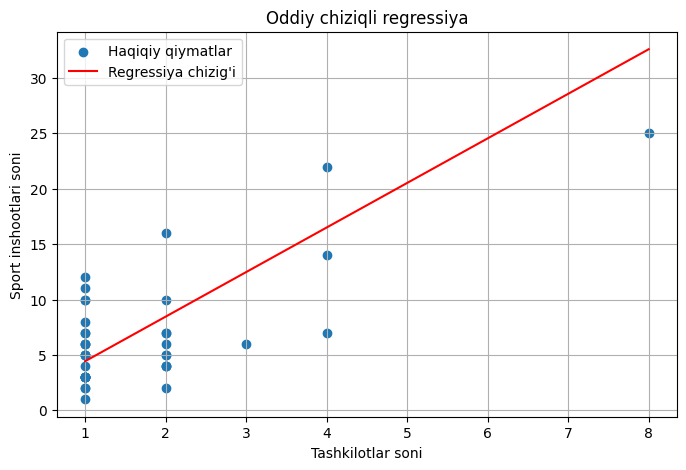

In [7]:
# Oddiy chiziqli regressiya grafigi

plt.figure(figsize=(8, 5))

# Haqiqiy qiymatlarni nuqtalar ko'rinishida chiqarish
plt.scatter(
    X_test_s["tashkilotlar_soni"],
    y_test_s,
    label="Haqiqiy qiymatlar"
)

# Bashorat qilingan regressiya chizig'i
# Grafik chiroyli chiqishi uchun X qiymatlarini tartiblaymiz
sorted_indices = np.argsort(X_test_s["tashkilotlar_soni"])

plt.plot(
    X_test_s["tashkilotlar_soni"].iloc[sorted_indices],
    y_pred_simple[sorted_indices],
    color="red",
    label="Regressiya chizig'i"
)

plt.xlabel("Tashkilotlar soni")
plt.ylabel("Sport inshootlari soni")
plt.title("Oddiy chiziqli regressiya")
plt.legend()
plt.grid()
plt.show()

In [8]:
# 2.2. Ko'p chiziqli regressiya
# Bir nechta mustaqil o'zgaruvchilardan foydalaniladi.

# Sonli va kategorik ustunlarni ajratish
numeric_features = [
    "tashkilotlar_soni",
    "binolar_soni"
]

categorical_features = ["Viloyat"]

# Ma'lumotlarni qayta ishlash
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Pipeline yaratish
multiple_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

# Modelni o'qitish
multiple_model.fit(X_train, y_train)

# Bashorat qilish
y_pred_multiple = multiple_model.predict(X_test)

print("Ko'p chiziqli regressiya modeli yaratildi.")

Ko'p chiziqli regressiya modeli yaratildi.


In [9]:
# 2.2. Ko'p chiziqli regressiya - bunda bir nechta mustaqil o'zgaruvchilar ishlatiladi.

# Viloyat ustunini One-Hot Encoding orqali sonli ko'rinishga o'tkazish
X_encoded = pd.get_dummies(
    X,
    columns=["Viloyat"],
    dtype=int
)

# Train va test ma'lumotlarini qayta ajratish
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

# Model yaratish
model_multi = LinearRegression()

# Modelni o'qitish
model_multi.fit(X_train, y_train)

# Bashorat qilish
y_pred_multi = model_multi.predict(X_test)

# Koeffitsiyentlarni chiqarish
print("Intercept:", model_multi.intercept_)

for feature, coef in zip(X_train.columns, model_multi.coef_):
    print(feature, ":", coef)

Intercept: -0.34708526130374295
tashkilotlar_soni : 0.48352811412257707
binolar_soni : 1.1404462580636356
Viloyat_Andijon viloyati : 1.9527948982966499
Viloyat_Buxoro viloyati : -0.3505462210126638
Viloyat_Farg'ona viloyati : -0.8039421915748606
Viloyat_Jizzax viloyati : 0.3307859078510458
Viloyat_Namangan viloyati : 1.1236853010580465
Viloyat_Navoiy viloyati : -1.4684976289585854
Viloyat_Qashqadaryo viloyati : -0.43436654428314886
Viloyat_Qoraqalpog‘iston  Respublikasi : -0.6717717305908968
Viloyat_Samarqand viloyati : -0.00753714146642789
Viloyat_Sirdaryo viloyati  : -0.3883074148220456
Viloyat_Surxondaryo viloyati  : -0.4001653693208793
Viloyat_Toshkent shahri : 0.9650667932079128
Viloyat_Toshkent viloyati : 0.4340413859329233
Viloyat_Xorazm viloyati : -0.28124004431706784


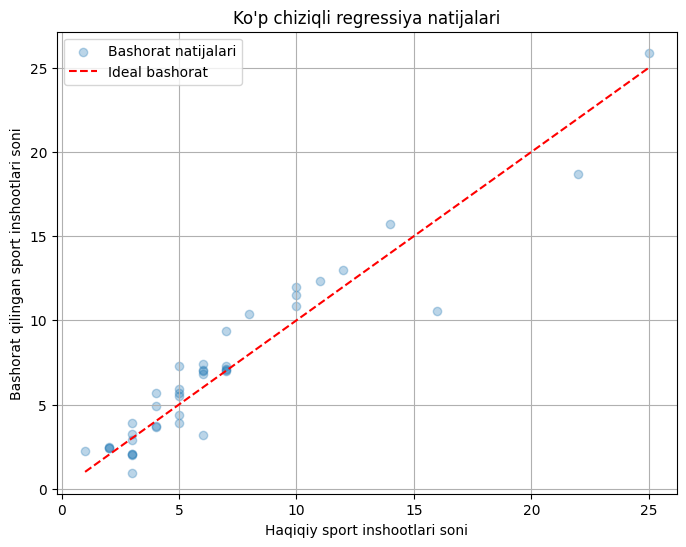

In [10]:
# Haqiqiy va bashorat qilingan qiymatlarni taqqoslash

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_multi,
    alpha=0.3,
    label="Bashorat natijalari"
)

# Ideal bashorat chizig'i
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Ideal bashorat"
)

plt.xlabel("Haqiqiy sport inshootlari soni")
plt.ylabel("Bashorat qilingan sport inshootlari soni")
plt.title("Ko'p chiziqli regressiya natijalari")

plt.legend()
plt.grid()
plt.show()

In [11]:
# 3. Polinomial regressiya - bu usul o'zgaruvchilar orasidagi egri chiziqli bog'liqliklarni ifodalaydi.

# Mustaqil va bog'liq o'zgaruvchilar
X_poly = df_model[["tashkilotlar_soni"]]
y_poly = df_model["sport_inshootlari_soni"]

# Train va testga ajratish
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly,
    y_poly,
    test_size=0.2,
    random_state=42
)

# Polinomial regressiya pipeline
polynomial_model = Pipeline(steps=[
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

# Modelni o'qitish
polynomial_model.fit(X_train_p, y_train_p)

# Bashorat qilish
y_pred_poly = polynomial_model.predict(X_test_p)

print("Polinomial regressiya modeli yaratildi.")

Polinomial regressiya modeli yaratildi.


In [12]:
# 3.1. Haqiqiy qiymatlar va bashoratlarni chiqarish

print("Haqiqiy qiymatlar:")
print(y_test_p.head(10).values)

print("\nBashorat qilingan qiymatlar:")
print(y_pred_poly[:10])

Haqiqiy qiymatlar:
[ 3 16  7  7  6  2  6 10  5 12]

Bashorat qilingan qiymatlar:
[ 4.92029823  7.59653485  4.92029823 14.35770504  4.92029823  4.92029823
  4.92029823  4.92029823  4.92029823  4.92029823]


In [13]:
# 3.2. Model koeffitsiyentlarini chiqarish

# Regressiya modelini ajratib olish
model_poly = polynomial_model.named_steps["regression"]

# Boshlang'ich qiymatni chiqarish
print("Intercept:", model_poly.intercept_)

# Koeffitsiyentlarni chiqarish
print("Koeffitsiyentlar:")
print(model_poly.coef_)

Intercept: 7.577639751552795
Koeffitsiyentlar:
[3.15973023 3.44535366]


In [14]:
# 3.3. Modelni baholash

from sklearn.metrics import mean_squared_error, r2_score

mse_poly = mean_squared_error(y_test_p, y_pred_poly)
r2_poly = r2_score(y_test_p, y_pred_poly)

print("MSE:", mse_poly)
print("R-squared:", r2_poly)

MSE: 14.399036881655023
R-squared: 0.42880920808801937


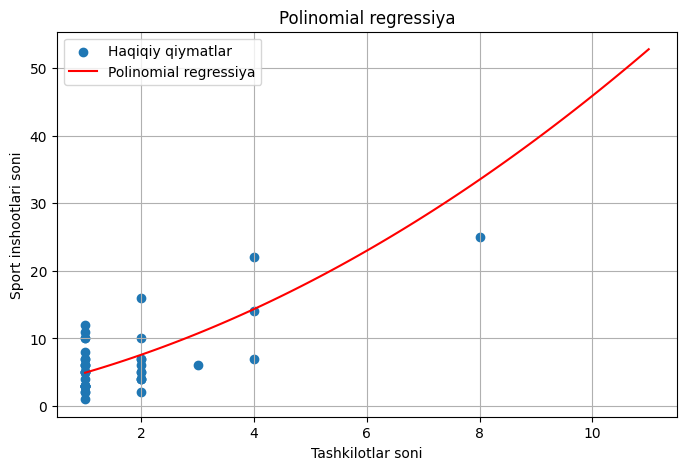

In [15]:
# 3.4. Haqiqiy qiymatlar va polinomial regressiya natijalarini grafikda ko'rsatish

# Grafik uchun qiymatlarni tartiblash
X_plot = pd.DataFrame({
    "tashkilotlar_soni": np.linspace(
        X_poly["tashkilotlar_soni"].min(),
        X_poly["tashkilotlar_soni"].max(),
        100
    )
})

# Grafik uchun bashorat qiymatlarini hisoblash
y_plot = polynomial_model.predict(X_plot)

plt.figure(figsize=(8, 5))

# Haqiqiy qiymatlar
plt.scatter(
    X_test_p["tashkilotlar_soni"],
    y_test_p,
    label="Haqiqiy qiymatlar"
)

# Polinomial regressiya chizig'i
plt.plot(
    X_plot["tashkilotlar_soni"],
    y_plot,
    color="red",
    label="Polinomial regressiya"
)

plt.xlabel("Tashkilotlar soni")
plt.ylabel("Sport inshootlari soni")
plt.title("Polinomial regressiya")
plt.legend()
plt.grid()
plt.show()

In [16]:
# 4. Ko'p o'zgaruvchan polinomli chiziqli regressiya

# Mustaqil o'zgaruvchilarni polinomial xususiyatlarga aylantirish
poly_multi = PolynomialFeatures(
    degree=2,
    include_bias=False
)

# Polinomial xususiyatlarni yaratish
X_poly_multi_train = poly_multi.fit_transform(X_train)
X_poly_multi_test = poly_multi.transform(X_test)

# Model yaratish
model_poly_multi = LinearRegression()

# Modelni o'qitish
model_poly_multi.fit(X_poly_multi_train, y_train)

# Bashorat qilish
y_pred_poly_multi = model_poly_multi.predict(
    X_poly_multi_test
)

# Polinomial xususiyatlar sonini chiqarish
print(
    "Polinomial xususiyatlar soni:",
    X_poly_multi_train.shape[1]
)

Polinomial xususiyatlar soni: 152


In [17]:
# 4.1. Haqiqiy va bashorat qilingan qiymatlarni chiqarish

# Haqiqiy qiymatlar
print("Haqiqiy qiymatlar:")
print(y_test.head(10).values)

# Bashorat qilingan qiymatlar
print("\nBashorat qilingan qiymatlar:")
print(y_pred_poly_multi[:10])

# Model ko'rsatkichlari
print("\nModel parametrlari:")
print("Intercept:", model_poly_multi.intercept_)
print("Koeffitsiyentlar:", model_poly_multi.coef_)

# Polinomial xususiyatlar soni
print("\nPolinomial xususiyatlar soni:",
      X_poly_multi_train.shape[1])

Haqiqiy qiymatlar:
[ 3 16  7  7  6  2  6 10  5 12]

Bashorat qilingan qiymatlar:
[ 2.82934325 10.41487491  7.81102864 19.97918609  8.14601494  2.66361714
  7.00503244 12.1907351   2.61740523 13.17404499]

Model parametrlari:
Intercept: 0.6407784018852238
Koeffitsiyentlar: [-0.76533851  1.17042735 -1.50745575  1.14207956 -0.88169983 -0.37136201
  0.2116047   0.56684247  0.16641491 -0.12058147  0.36861936  1.204149
  0.43026684 -1.06298795 -0.40604971  0.26015989  0.28572421  0.02571341
  2.78584441 -1.78031898  0.13479399  0.67144249 -0.96947815 -1.81315613
  0.00911144 -0.77730223 -0.13732252 -1.47388555 -1.29616997  5.1483503
 -0.4305062  -0.83674141 -0.02107437  0.20412559  0.23874358  0.27687559
  0.12805697  0.38725852  0.20719546  0.00912693  0.22740758 -0.2027236
  0.14015618  0.17549347 -1.25337658  0.46821489  0.16387278 -1.50745575
  0.          0.          0.          0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          1.1

In [18]:
# 4.2. Model sifatini baholash (MSE va R-squared)

mse_poly_multi = mean_squared_error(
    y_test, y_pred_poly_multi
)

r2_poly_multi = r2_score(
    y_test, y_pred_poly_multi
)

print("MSE:", mse_poly_multi)
print("R-squared:", r2_poly_multi)

MSE: 8.660703229129364
R-squared: 0.6564413316932589


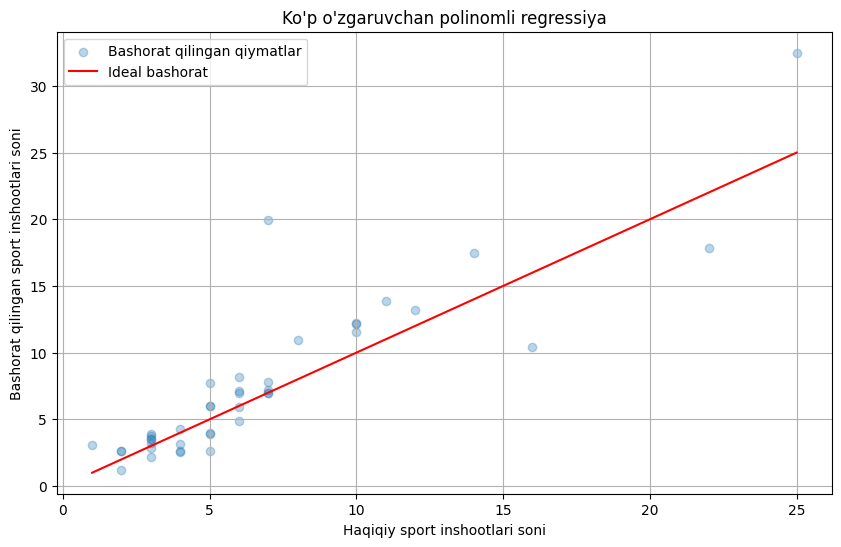

In [19]:
# 4.3. Grafik orqali natijalarni ko'rish

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred_poly_multi,
    alpha=0.3,
    label="Bashorat qilingan qiymatlar"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    label="Ideal bashorat"
)

plt.xlabel("Haqiqiy sport inshootlari soni")
plt.ylabel("Bashorat qilingan sport inshootlari soni")
plt.title("Ko'p o'zgaruvchan polinomli regressiya")
plt.legend()
plt.grid()
plt.show()

In [20]:
# 4.4. Natijalarni jadvalda ko'rish

natijalar = pd.DataFrame({
    "Haqiqiy sport inshootlari soni": y_test.values[:10],
    "Bashorat qilingan sport inshootlari soni": y_pred_poly_multi[:10]
})

print(natijalar)

   Haqiqiy sport inshootlari soni  Bashorat qilingan sport inshootlari soni
0                               3                                  2.829343
1                              16                                 10.414875
2                               7                                  7.811029
3                               7                                 19.979186
4                               6                                  8.146015
5                               2                                  2.663617
6                               6                                  7.005032
7                              10                                 12.190735
8                               5                                  2.617405
9                              12                                 13.174045


In [21]:
# 5. Pipeline - bir nechta amallarni yagona ketma-ketlikda bajarish.

# Biz quyidagi amallarni birlashtiramiz:
# 1. StandardScaler — ma'lumotlarni standartlashtirish.
# 2. PolynomialFeatures — polinomial xususiyatlarni yaratish.
# 3. LinearRegression — regressiya modelini yaratish.

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ('model', LinearRegression())
])

# Modelni o'qitish
pipeline.fit(X_train, y_train)

# Bashorat
y_pred_pipeline = pipeline.predict(X_test)

print("Pipeline muvaffaqiyatli bajarildi.")

Pipeline muvaffaqiyatli bajarildi.


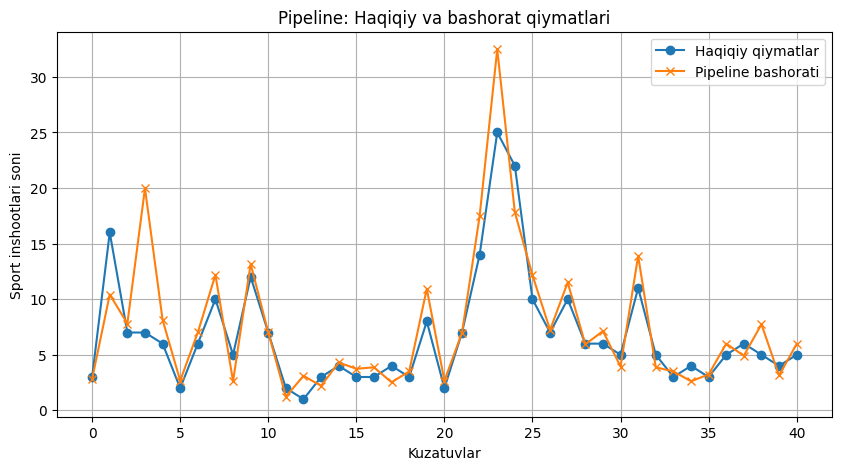

In [22]:
# Haqiqiy va bashorat qilingan qiymatlarni grafikda taqqoslash

plt.figure(figsize=(10, 5))

plt.plot(
    np.array(y_test)[:50],
    label="Haqiqiy qiymatlar",
    marker="o"
)

plt.plot(
    y_pred_pipeline[:50],
    label="Pipeline bashorati",
    marker="x"
)

plt.title("Pipeline: Haqiqiy va bashorat qiymatlari")
plt.xlabel("Kuzatuvlar")
plt.ylabel("Sport inshootlari soni")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# 6. Namunaviy baholash choralari - Model sifatini baholash uchun ikkita asosiy ko‘rsatkichdan foydalanamiz.

# 6.1. O‘rtacha kvadratik xato (MSE)

# MSE qiymati qancha kichik bo‘lsa, bashoratlarning kvadratik xatoliklari shuncha kichik bo‘ladi.

mse = mean_squared_error(
    y_test,
    y_pred_pipeline
)

print("MSE:", mse)

MSE: 8.660703229128897


In [26]:
# 6.2. R-squared (R²) - Model bog‘liq o‘zgaruvchidagi o‘zgarishlarning qancha qismini tushuntirishini ko‘rsatadi.

# R² qiymati 1 ga yaqinlashgani sari modelning tushuntirish qobiliyati yaxshiroq bo‘ladi.
# Manfiy qiymat ham kuzatilishi mumkin.

r2 = r2_score(
    y_test,
    y_pred_pipeline
)

print("R-squared:", r2)

R-squared: 0.6564413316932775


In [27]:
# 6.3. Barcha modellarni taqqoslash

models = {
    "Oddiy chiziqli regressiya": (y_test_s, y_pred_simple),
    "Ko'p chiziqli regressiya": (y_test, y_pred_multi),
    "Polinomial regressiya": (y_test_p, y_pred_poly),
    "Ko'p o'zgaruvchili polinomial regressiya": (y_test, y_pred_poly_multi),
    "Pipeline": (y_test, y_pred_pipeline)
}

results = []

for name, (actual, prediction) in models.items():

    mse = mean_squared_error(actual, prediction)
    r2 = r2_score(actual, prediction)

    results.append({
        "Model": name,
        "MSE": mse,
        "R-squared": r2
    })

results_df = pd.DataFrame(results)

print(results_df)

                                      Model        MSE  R-squared
0                 Oddiy chiziqli regressiya  16.003340   0.365169
1                  Ko'p chiziqli regressiya   2.460690   0.902388
2                     Polinomial regressiya  14.399037   0.428809
3  Ko'p o'zgaruvchili polinomial regressiya   8.660703   0.656441
4                                  Pipeline   8.660703   0.656441


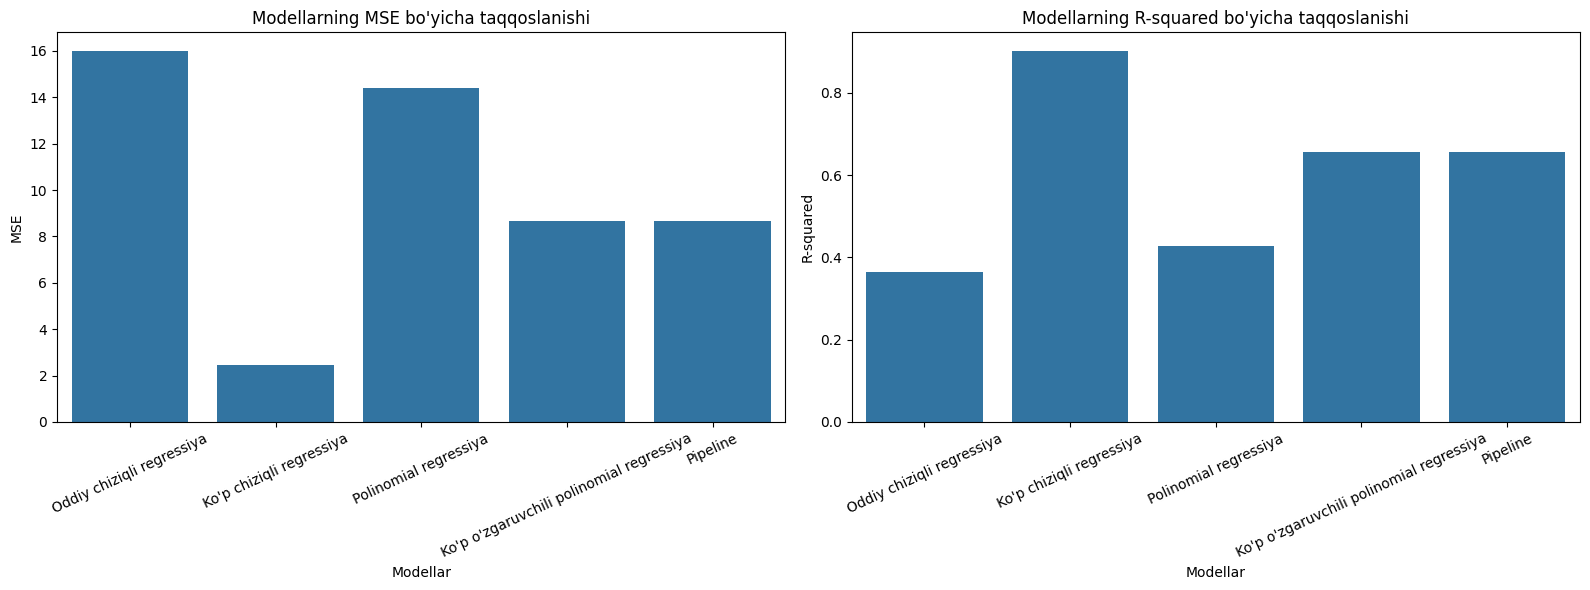

In [28]:
# 6.4. Modellarning MSE va R-squared bo'yicha taqqoslanishi

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. MSE grafigi
sns.barplot(
    data=results_df,
    x="Model",
    y="MSE",
    ax=axes[0]
)

axes[0].set_title("Modellarning MSE bo'yicha taqqoslanishi")
axes[0].set_xlabel("Modellar")
axes[0].set_ylabel("MSE")
axes[0].tick_params(axis="x", rotation=25)

# 2. R-squared grafigi
sns.barplot(
    data=results_df,
    x="Model",
    y="R-squared",
    ax=axes[1]
)

axes[1].set_title("Modellarning R-squared bo'yicha taqqoslanishi")
axes[1].set_xlabel("Modellar")
axes[1].set_ylabel("R-squared")
axes[1].tick_params(axis="x", rotation=25)

# Grafiklarni tartibga keltirish
plt.tight_layout()
plt.show()

In [29]:
# 7. Bashorat qilish va qaror qabul qilish

# Yangi tumanlar ma'lumotlari
new_districts = pd.DataFrame({
    "tashkilotlar_soni": [3, 5, 4],
    "binolar_soni": [8, 12, 10],
    "Viloyat": [
        "Toshkent viloyati",
        "Samarqand viloyati",
        "Farg'ona viloyati"
    ]
})

# Viloyat ustunini One-Hot Encoding qilish
new_districts_encoded = pd.get_dummies(
    new_districts,
    columns=["Viloyat"],
    dtype=int
)

# Yangi ma'lumotlarni model o'rgangan ustunlarga moslashtirish
new_districts_encoded = new_districts_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Pipeline orqali bashorat qilish
predictions = pipeline.predict(new_districts_encoded)

# Bashorat natijalarini jadvalga qo'shish
new_districts["bashorat_qilingan_inshootlar_soni"] = predictions

# Natijalarni chiqarish
print("YANGI TUMANLAR UCHUN BASHORAT NATIJALARI")
print("-" * 55)

for index, row in new_districts.iterrows():

    print(f"\nViloyat: {row['Viloyat']}")
    print(f"Tashkilotlar soni: {row['tashkilotlar_soni']}")
    print(f"Binolar soni: {row['binolar_soni']}")
    print(
        f"Bashorat qilingan sport inshootlari soni: "
        f"{row['bashorat_qilingan_inshootlar_soni']:.2f} ta"
    )

YANGI TUMANLAR UCHUN BASHORAT NATIJALARI
-------------------------------------------------------

Viloyat: Toshkent viloyati
Tashkilotlar soni: 3
Binolar soni: 8
Bashorat qilingan sport inshootlari soni: 11.19 ta

Viloyat: Samarqand viloyati
Tashkilotlar soni: 5
Binolar soni: 12
Bashorat qilingan sport inshootlari soni: 14.13 ta

Viloyat: Farg'ona viloyati
Tashkilotlar soni: 4
Binolar soni: 10
Bashorat qilingan sport inshootlari soni: 14.32 ta


In [30]:
# ANOVA testi - Sport inshootlari sonining hududlar bo'yicha farqini tekshirish

import pandas as pd
import numpy as np
from scipy.stats import f_oneway

anova_results = []

# Har bir viloyat uchun sport inshootlari sonini ajratib olish
groups = [
    group["sport_inshootlari_soni"].dropna().values
    for name, group in df_model.groupby("Viloyat")
]

# ANOVA testini bajarish
f_stat, p_value = f_oneway(*groups)

# Natijalarni saqlash
anova_results.append({
    "Taqqoslash": "Viloyatlar bo'yicha sport inshootlari soni",
    "F-statistic": f_stat,
    "P-value": p_value,
    "Natija": "Ahamiyatli" if p_value < 0.05 else "Ahamiyatli emas"
})

# Natijalarni jadvalda chiqarish
anova_df = pd.DataFrame(anova_results)

print("ANOVA TEST NATIJALARI:")
print(anova_df.to_string(index=False))

ANOVA TEST NATIJALARI:
                                Taqqoslash  F-statistic  P-value          Natija
Viloyatlar bo'yicha sport inshootlari soni     1.710469 0.061511 Ahamiyatli emas


In [31]:
# P-value natijalarini chiqarish
# Bu alohida test emas, ANOVA testi natijasida olingan qiymatni tahlil qilishdir.

print("P-VALUE TAHLILI")
print("-" * 45)

for index, row in anova_df.iterrows():

    print(f"\nTaqqoslash: {row['Taqqoslash']}")
    print(f"F-statistic: {row['F-statistic']:.4f}")
    print(f"P-value: {row['P-value']:.12e}")

    if row['P-value'] < 0.05:
        print("Xulosa: Statistik jihatdan ahamiyatli.")
    else:
        print("Xulosa: Statistik jihatdan ahamiyatli emas.")

P-VALUE TAHLILI
---------------------------------------------

Taqqoslash: Viloyatlar bo'yicha sport inshootlari soni
F-statistic: 1.7105
P-value: 6.151084062497e-02
Xulosa: Statistik jihatdan ahamiyatli emas.


In [ ]:
# Chi-Square (χ²) testi - Kategorik ustunlar o'rtasidagi bog'liqlikni tekshirish

from scipy.stats import chi2_contingency

# Kategorik ustunlar
categorical_columns = [
    "Hudud",
    "Tuman(shahar)",
    "Tashkilot"
]

chi_results = []

# Har bir kategorik ustun uchun Chi-Square testi
for column in categorical_columns:

    contingency_table = pd.crosstab(
        df[column],
        df["Sport inshoati turi"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_results.append({
        "Ustun": column,
        "Chi2-statistic": chi2,
        "P-value": p_value,
        "Degrees of Freedom": dof,
        "Natija": "Bog'liqlik mavjud" if p_value < 0.05
                  else "Bog'liqlik aniqlanmadi"
    })

chi_df = pd.DataFrame(chi_results)

print("CHI-SQUARE TEST NATIJALARI:")
print(chi_df.to_string(index=False))

CHI-SQUARE TEST NATIJALARI:
        Ustun  Chi2-statistic      P-value  Degrees of Freedom            Natija
        Hudud      418.795989 2.038774e-18                 195 Bog'liqlik mavjud
Tuman(shahar)     3314.406119 9.073954e-05                3015 Bog'liqlik mavjud
    Tashkilot     5462.533860 1.113047e-18                4575 Bog'liqlik mavjud
